In [1]:
# ==========================================
# 1. GPU AND ENVIRONMENT VERIFICATION
# ==========================================

import sys
import torch
import transformers
import datasets
import evaluate
import accelerate

print("Python executable:", sys.executable)
print("-" * 50)

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())
print("-" * 50)

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

    # Test GPU computation
    x = torch.randn(1000, 1000, device="cuda")
    y = torch.matmul(x, x)

    print("Tensor device:", y.device)
    print("GPU computation test: SUCCESS")
else:
    print("GPU not detected by Jupyter!")
    

Python executable: c:\Users\sansm\AppData\Local\Programs\Python\Python312\python.exe
--------------------------------------------------
PyTorch version: 2.14.1+cu132
Transformers version: 5.23.0
CUDA available: True
--------------------------------------------------
GPU name: NVIDIA GeForce RTX 5050 Laptop GPU
GPU memory: 7.96 GB
Tensor device: cuda:0
GPU computation test: SUCCESS


In [2]:
# ==========================================
# 2. LOAD ORIGINAL MELD DATASET
# ==========================================

import pandas as pd
from pathlib import Path

# Locate project directories
current_dir = Path.cwd()

print("Current working directory:", current_dir)

# Find the raw dataset folder
if (current_dir / "data" / "raw").exists():
    data_path = current_dir / "data" / "raw"
elif (current_dir.parent / "data" / "raw").exists():
    data_path = current_dir.parent / "data" / "raw"
else:
    raise FileNotFoundError("Could not find data/raw folder")

print("Dataset folder:", data_path)

# Load original MELD datasets
train_df = pd.read_csv(data_path / "train_sent_emo.csv")
dev_df = pd.read_csv(data_path / "dev_sent_emo.csv")
test_df = pd.read_csv(data_path / "test_sent_emo.csv")

print("\nDataset loaded successfully!")
print("-" * 50)
print("Training shape:", train_df.shape)
print("Validation shape:", dev_df.shape)
print("Test shape:", test_df.shape)

Current working directory: c:\Users\sansm\Desktop\NLP PROJECT CHATGPT\Conversation_Sentiment_Analysis\notebooks
Dataset folder: c:\Users\sansm\Desktop\NLP PROJECT CHATGPT\Conversation_Sentiment_Analysis\data\raw

Dataset loaded successfully!
--------------------------------------------------
Training shape: (9989, 11)
Validation shape: (1109, 11)
Test shape: (2610, 11)


In [3]:
# ==========================================
# 3. DATASET INSPECTION
# ==========================================

print("TRAIN DATA")
print("-" * 50)
print(train_df.head(3))

print("\nDATASET COLUMNS")
print(train_df.columns.tolist())

print("\nSENTIMENT LABEL DISTRIBUTION")
print(train_df["Sentiment"].value_counts())

print("\nSENTIMENT LABELS")
print(train_df["Sentiment"].unique())

print("\nMISSING UTTERANCES")
print("Train:", train_df["Utterance"].isna().sum())
print("Validation:", dev_df["Utterance"].isna().sum())
print("Test:", test_df["Utterance"].isna().sum())

TRAIN DATA
--------------------------------------------------
   Sr No.                                          Utterance          Speaker  \
0       1  also I was the point person on my company’s tr...         Chandler   
1       2                   You must’ve had your hands full.  The Interviewer   
2       3                            That I did. That I did.         Chandler   

   Emotion Sentiment  Dialogue_ID  Utterance_ID  Season  Episode  \
0  neutral   neutral            0             0       8       21   
1  neutral   neutral            0             1       8       21   
2  neutral   neutral            0             2       8       21   

      StartTime       EndTime  
0  00:16:16,059  00:16:21,731  
1  00:16:21,940  00:16:23,442  
2  00:16:23,442  00:16:26,389  

DATASET COLUMNS
['Sr No.', 'Utterance', 'Speaker', 'Emotion', 'Sentiment', 'Dialogue_ID', 'Utterance_ID', 'Season', 'Episode', 'StartTime', 'EndTime']

SENTIMENT LABEL DISTRIBUTION
Sentiment
neutral     4710
neg

In [4]:
# ==========================================
# 4. SENTIMENT LABEL ENCODING
# ==========================================

label2id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

id2label = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

# Normalize sentiment labels
for df in [train_df, dev_df, test_df]:
    df["Sentiment"] = df["Sentiment"].str.lower().str.strip()

    df["label"] = df["Sentiment"].map(label2id)

print("Label mapping:", label2id)
print("-" * 50)

print("Training label counts:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation label counts:")
print(dev_df["label"].value_counts().sort_index())

print("\nTest label counts:")
print(test_df["label"].value_counts().sort_index())

# Check for unmapped labels
print("\nUnmapped training labels:", train_df["label"].isna().sum())
print("Unmapped validation labels:", dev_df["label"].isna().sum())
print("Unmapped test labels:", test_df["label"].isna().sum())

Label mapping: {'negative': 0, 'neutral': 1, 'positive': 2}
--------------------------------------------------
Training label counts:
label
0    2945
1    4710
2    2334
Name: count, dtype: int64

Validation label counts:
label
0    406
1    470
2    233
Name: count, dtype: int64

Test label counts:
label
0     833
1    1256
2     521
Name: count, dtype: int64

Unmapped training labels: 0
Unmapped validation labels: 0
Unmapped test labels: 0


In [5]:
# ==========================================
# 5. LOAD DISTILBERT TOKENIZER
# ==========================================

from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Model:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)

Tokenizer loaded successfully!
Model: distilbert/distilbert-base-uncased
Vocabulary size: 30522


In [6]:
# ==========================================
# 6. TOKENIZE DATASETS
# ==========================================

MAX_LENGTH = 128

# Tokenize text
train_encodings = tokenizer(
    train_df["Utterance"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

dev_encodings = tokenizer(
    dev_df["Utterance"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

test_encodings = tokenizer(
    test_df["Utterance"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

print("Tokenization completed successfully!")
print("-" * 50)
print("Training samples:", len(train_encodings["input_ids"]))
print("Validation samples:", len(dev_encodings["input_ids"]))
print("Test samples:", len(test_encodings["input_ids"]))

print("\nSample token IDs:")
print(train_encodings["input_ids"][0][:20])

print("\nSample attention mask:")
print(train_encodings["attention_mask"][0][:20])

Tokenization completed successfully!
--------------------------------------------------
Training samples: 9989
Validation samples: 1109
Test samples: 2610

Sample token IDs:
[101, 2036, 1045, 2001, 1996, 2391, 2711, 2006, 2026, 2194, 1521, 1055, 6653, 2013, 1996, 1047, 2140, 1011, 1019, 2000]

Sample attention mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [7]:
# ==========================================
# 7. CREATE PYTORCH DATASETS
# ==========================================

import torch
from torch.utils.data import Dataset

class MELDDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item

# Create PyTorch datasets
train_dataset = MELDDataset(
    train_encodings,
    train_df["label"].tolist()
)

dev_dataset = MELDDataset(
    dev_encodings,
    dev_df["label"].tolist()
)

test_dataset = MELDDataset(
    test_encodings,
    test_df["label"].tolist()
)

print("PyTorch datasets created successfully!")
print("-" * 50)
print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(dev_dataset))
print("Test dataset:", len(test_dataset))

# Inspect one sample
sample = train_dataset[0]

print("\nSample keys:", sample.keys())
print("Input IDs shape:", sample["input_ids"].shape)
print("Attention mask shape:", sample["attention_mask"].shape)
print("Label:", sample["labels"].item())

PyTorch datasets created successfully!
--------------------------------------------------
Train dataset: 9989
Validation dataset: 1109
Test dataset: 2610

Sample keys: dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])
Input IDs shape: torch.Size([128])
Attention mask shape: torch.Size([128])
Label: 1


In [8]:
# ==========================================
# 8. LOAD PRETRAINED DISTILBERT MODEL
# ==========================================

from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

# Move model to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("DistilBERT model loaded successfully!")
print("-" * 50)
print("Model:", MODEL_NAME)
print("Number of sentiment classes:", model.config.num_labels)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!
--------------------------------------------------
Model: distilbert/distilbert-base-uncased
Number of sentiment classes: 3
Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [9]:
from torch.utils.data import DataLoader

# Training batch size
BATCH_SIZE = 8

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Training hyperparameters
EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

print("DataLoaders created successfully!")
print("-" * 50)
print("Training batches:", len(train_loader))
print("Validation batches:", len(dev_loader))
print("Test batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

DataLoaders created successfully!
--------------------------------------------------
Training batches: 1249
Validation batches: 139
Test batches: 327
Batch size: 8
Epochs: 3
Learning rate: 2e-05


In [10]:
from torch.utils.data import DataLoader

# Batch sizes suitable for our GPU
BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Training configuration
EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

print("Training configuration ready!")
print("-" * 40)
print("Training batches:", len(train_loader))
print("Validation batches:", len(dev_loader))
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

if torch.cuda.is_available():
    print("\nGPU memory allocated:",
          round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
    print("GPU memory reserved:",
          round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

Training configuration ready!
----------------------------------------
Training batches: 1249
Validation batches: 70
Batch size: 8
Epochs: 3
Learning rate: 2e-05
Weight decay: 0.01

GPU memory allocated: 0.29 GB
GPU memory reserved: 0.32 GB


In [11]:
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Total training steps
total_training_steps = len(train_loader) * EPOCHS

# Warm-up steps (10% of total training steps)
warmup_steps = int(0.1 * total_training_steps)

# Learning-rate scheduler
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("Optimizer and scheduler initialized!")
print("-" * 40)
print("Optimizer: AdamW")
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)
print("Initial learning rate:", LEARNING_RATE)

Optimizer and scheduler initialized!
----------------------------------------
Optimizer: AdamW
Total training steps: 3747
Warmup steps: 374
Initial learning rate: 2e-05


In [12]:
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

def train_one_epoch(model, train_loader, optimizer, scheduler, device):
    model.train()
    total_loss = 0

    progress_bar = tqdm(train_loader, desc="Training")

    for batch in progress_bar:
        # Move batch to GPU
        batch = {k: v.to(device) for k, v in batch.items()}

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(**batch)
        loss = outputs.loss

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # Update weights
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    average_loss = total_loss / len(train_loader)
    return average_loss


def evaluate_model(model, dev_loader, device):
    model.eval()

    total_loss = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(dev_loader, desc="Validation"):
            batch = {k: v.to(device) for k, v in batch.items()}

            outputs = model(**batch)

            total_loss += outputs.loss.item()

            predictions = torch.argmax(outputs.logits, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(batch["labels"].cpu().numpy())

    average_loss = total_loss / len(dev_loader)

    accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(
        all_labels, all_predictions, average="macro"
    )
    weighted_f1 = f1_score(
        all_labels, all_predictions, average="weighted"
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }


print("Training and validation functions created successfully!")

Training and validation functions created successfully!


In [13]:
from pathlib import Path
import copy
import torch

# Find project root
if (Path.cwd() / "models").exists():
    project_root = Path.cwd()
elif (Path.cwd().parent / "models").exists():
    project_root = Path.cwd().parent
else:
    project_root = Path.cwd().parent

MODEL_SAVE_PATH = project_root / "models" / "distilbert_meld_sentiment"
MODEL_SAVE_PATH.mkdir(parents=True, exist_ok=True)

training_history = []
best_macro_f1 = 0.0

for epoch in range(EPOCHS):
    print(f"\n{'='*60}")
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"{'='*60}")

    # Train
    train_loss = train_one_epoch(
        model, train_loader, optimizer, scheduler, device
    )

    # Validate
    val_metrics = evaluate_model(model, dev_loader, device)

    print(f"\nEpoch {epoch + 1} Results:")
    print(f"Training Loss : {train_loss:.4f}")
    print(f"Validation Loss: {val_metrics['loss']:.4f}")
    print(f"Validation Accuracy: {val_metrics['accuracy']:.4f}")
    print(f"Validation Macro F1: {val_metrics['macro_f1']:.4f}")
    print(f"Validation Weighted F1: {val_metrics['weighted_f1']:.4f}")

    # Store history
    epoch_record = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **{f"val_{k}": v for k, v in val_metrics.items()}
    }
    training_history.append(epoch_record)

    # Save best model based on validation Macro F1
    if val_metrics["macro_f1"] > best_macro_f1:
        best_macro_f1 = val_metrics["macro_f1"]

        model.save_pretrained(MODEL_SAVE_PATH)
        tokenizer.save_pretrained(MODEL_SAVE_PATH)

        print("\n🏆 New best model saved!")
        print("Best Validation Macro F1:", round(best_macro_f1, 4))

print("\n" + "="*60)
print("TRAINING COMPLETE!")
print("="*60)
print("Best Validation Macro F1:", round(best_macro_f1, 4))
print("Saved model location:", MODEL_SAVE_PATH)


Epoch 1/3


Training:   0%|          | 0/1249 [00:00<?, ?it/s]

Validation:   0%|          | 0/70 [00:00<?, ?it/s]


Epoch 1 Results:
Training Loss : 0.8311
Validation Loss: 0.7734
Validation Accuracy: 0.6700
Validation Macro F1: 0.6543
Validation Weighted F1: 0.6699


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


🏆 New best model saved!
Best Validation Macro F1: 0.6543

Epoch 2/3


... (6 outputs left out)

Validation:   0%|          | 0/70 [00:00<?, ?it/s]


Epoch 3 Results:
Training Loss : 0.5230
Validation Loss: 0.8521
Validation Accuracy: 0.6781
Validation Macro F1: 0.6575
Validation Weighted F1: 0.6746


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


🏆 New best model saved!
Best Validation Macro F1: 0.6575

TRAINING COMPLETE!
Best Validation Macro F1: 0.6575
Saved model location: c:\Users\sansm\Desktop\NLP PROJECT CHATGPT\Conversation_Sentiment_Analysis\models\distilbert_meld_sentiment


In [14]:
import pandas as pd

history_df = pd.DataFrame(training_history)

display(
    history_df.round(4)
)

print("\nBest epoch based on Macro F1:")
print(
    history_df.loc[
        history_df["val_macro_f1"].idxmax()
    ]
)

,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_weighted_f1
0,1,0.8311,0.7734,0.6700,0.6543,0.6699
1,2,0.6639,0.7713,0.6790,0.6564,0.6747
2,3,0.5230,0.8521,0.6781,0.6575,0.6746



Best epoch based on Macro F1:
epoch              3.000000
train_loss         0.523015
val_loss           0.852060
val_accuracy       0.678088
val_macro_f1       0.657466
val_weighted_f1    0.674571
Name: 2, dtype: float64


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.6517    0.6084    0.6293       406
     Neutral     0.7203    0.8000    0.7581       470
    Positive     0.6202    0.5536    0.5850       233

    accuracy                         0.6781      1109
   macro avg     0.6641    0.6540    0.6575      1109
weighted avg     0.6742    0.6781    0.6746      1109



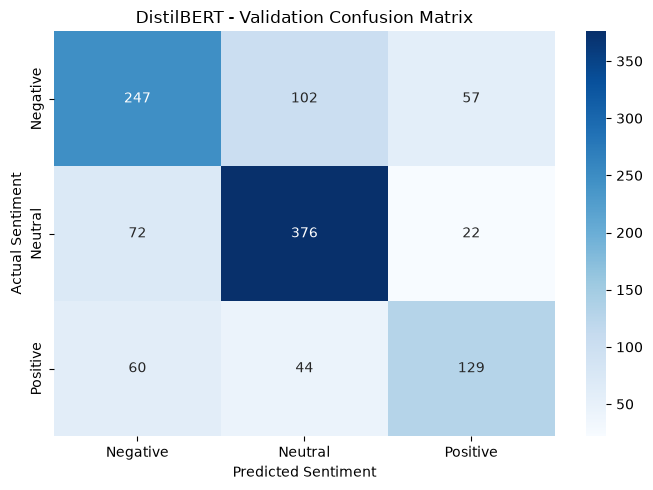

In [15]:
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Load the best saved checkpoint (Epoch 2)
best_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_SAVE_PATH
).to(device)

best_model.eval()

all_preds = []
all_true = []

with torch.no_grad():
    for batch in dev_loader:
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = best_model(**batch)
        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_true.extend(batch["labels"].cpu().numpy())

# Detailed class-wise report
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        all_true,
        all_preds,
        target_names=["Negative", "Neutral", "Positive"],
        digits=4
    )
)

# Confusion matrix
cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("DistilBERT - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [16]:
def add_conversation_context(df, previous_turns=2):
    df = df.copy()

    # Sort utterances within each dialogue
    df = df.sort_values(
        ["Dialogue_ID", "Utterance_ID"]
    ).copy()

    contextual_texts = []

    for dialogue_id, group in df.groupby("Dialogue_ID", sort=False):
        utterances = group["Utterance"].fillna("").tolist()
        speakers = group["Speaker"].fillna("Unknown").tolist()

        for i in range(len(utterances)):
            start = max(0, i - previous_turns)

            context_parts = []

            # Include preceding turns
            for j in range(start, i):
                context_parts.append(
                    f"Previous Speaker: {speakers[j]} | "
                    f"Previous Utterance: {utterances[j]}"
                )

            # Include current target utterance
            context_parts.append(
                f"Current Speaker: {speakers[i]} | "
                f"Current Utterance: {utterances[i]}"
            )

            contextual_texts.append(" [SEP] ".join(context_parts))

    df["Context_Text"] = contextual_texts
    return df


# Create contextual datasets without changing originals
train_context_df = add_conversation_context(train_df, previous_turns=2)
dev_context_df = add_conversation_context(dev_df, previous_turns=2)
test_context_df = add_conversation_context(test_df, previous_turns=2)

print("Contextual datasets created!")
print("Train:", train_context_df.shape)
print("Validation:", dev_context_df.shape)
print("Test:", test_context_df.shape)

print("\nExample context:")
print(train_context_df["Context_Text"].iloc[5])

Contextual datasets created!
Train: (9989, 13)
Validation: (1109, 13)
Test: (2610, 13)

Example context:
Previous Speaker: The Interviewer | Previous Utterance: So let’s talk a little bit about your duties. [SEP] Previous Speaker: Chandler | Previous Utterance: My duties?  All right. [SEP] Current Speaker: The Interviewer | Current Utterance: Now you’ll be heading a whole division, so you’ll have a lot of duties.


In [17]:
# Tokenize contextual utterances
train_context_encodings = tokenizer(
    train_context_df["Context_Text"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

dev_context_encodings = tokenizer(
    dev_context_df["Context_Text"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

test_context_encodings = tokenizer(
    test_context_df["Context_Text"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

print("Context tokenization completed!")
print("Training samples:", len(train_context_encodings["input_ids"]))
print("Validation samples:", len(dev_context_encodings["input_ids"]))
print("Test samples:", len(test_context_encodings["input_ids"]))

Context tokenization completed!
Training samples: 9989
Validation samples: 1109
Test samples: 2610


In [18]:
# Create PyTorch datasets using contextual encodings
train_context_dataset = MELDDataset(
    train_context_encodings,
    train_context_df["label"].tolist()
)

dev_context_dataset = MELDDataset(
    dev_context_encodings,
    dev_context_df["label"].tolist()
)

test_context_dataset = MELDDataset(
    test_context_encodings,
    test_context_df["label"].tolist()
)

# Create contextual DataLoaders
train_context_loader = DataLoader(
    train_context_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

dev_context_loader = DataLoader(
    dev_context_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Contextual datasets and DataLoaders created!")
print("-" * 45)
print("Training samples:", len(train_context_dataset))
print("Validation samples:", len(dev_context_dataset))
print("Training batches:", len(train_context_loader))
print("Validation batches:", len(dev_context_loader))

Contextual datasets and DataLoaders created!
---------------------------------------------
Training samples: 9989
Validation samples: 1109
Training batches: 1249
Validation batches: 70


In [19]:
# Initialize a fresh DistilBERT for the context experiment
context_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

context_model.to(device)

print("Contextual DistilBERT initialized!")
print("-" * 45)
print("Model:", MODEL_NAME)
print("Classes:", context_model.config.num_labels)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Contextual DistilBERT initialized!
---------------------------------------------
Model: distilbert/distilbert-base-uncased
Classes: 3
Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [20]:
# Context experiment optimizer
context_optimizer = AdamW(
    context_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Total steps for context training
context_total_steps = len(train_context_loader) * EPOCHS

context_warmup_steps = int(0.1 * context_total_steps)

# Context experiment scheduler
context_scheduler = get_linear_schedule_with_warmup(
    context_optimizer,
    num_warmup_steps=context_warmup_steps,
    num_training_steps=context_total_steps
)

print("Context optimizer and scheduler ready!")
print("-" * 45)
print("Total training steps:", context_total_steps)
print("Warmup steps:", context_warmup_steps)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)

Context optimizer and scheduler ready!
---------------------------------------------
Total training steps: 3747
Warmup steps: 374
Learning rate: 2e-05
Epochs: 3


In [21]:
# Updated training configuration for Context DistilBERT

CONTEXT_EPOCHS = 5
EARLY_STOPPING_PATIENCE = 2

CONTEXT_LEARNING_RATE = 2e-5
CONTEXT_WEIGHT_DECAY = 0.01

# Reinitialize optimizer
context_optimizer = AdamW(
    context_model.parameters(),
    lr=CONTEXT_LEARNING_RATE,
    weight_decay=CONTEXT_WEIGHT_DECAY
)

# Recreate scheduler for 5 epochs
context_total_steps = len(train_context_loader) * CONTEXT_EPOCHS
context_warmup_steps = int(0.1 * context_total_steps)

context_scheduler = get_linear_schedule_with_warmup(
    context_optimizer,
    num_warmup_steps=context_warmup_steps,
    num_training_steps=context_total_steps
)

print("Updated Context Model configuration")
print("-" * 45)
print("Epochs:", CONTEXT_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Learning rate:", CONTEXT_LEARNING_RATE)
print("Total training steps:", context_total_steps)
print("Warmup steps:", context_warmup_steps)

Updated Context Model configuration
---------------------------------------------
Epochs: 5
Early stopping patience: 2
Learning rate: 2e-05
Total training steps: 6245
Warmup steps: 624


In [22]:
# Context DistilBERT training with early stopping

context_training_history = []

context_best_macro_f1 = -1.0
epochs_without_improvement = 0

for epoch in range(CONTEXT_EPOCHS):

    print(f"\n{'='*60}")
    print(f"Context Model - Epoch {epoch + 1}/{CONTEXT_EPOCHS}")
    print(f"{'='*60}")

    # 1. Train
    context_train_loss = train_one_epoch(
        context_model,
        train_context_loader,
        context_optimizer,
        context_scheduler,
        device
    )

    # 2. Validate
    context_val_metrics = evaluate_model(
        context_model,
        dev_context_loader,
        device
    )

    # 3. Display metrics
    print(f"\nEpoch {epoch + 1} Results:")
    print(f"Training Loss: {context_train_loss:.4f}")
    print(f"Validation Loss: {context_val_metrics['loss']:.4f}")
    print(f"Validation Accuracy: {context_val_metrics['accuracy']:.4f}")
    print(f"Validation Macro F1: {context_val_metrics['macro_f1']:.4f}")
    print(f"Validation Weighted F1: {context_val_metrics['weighted_f1']:.4f}")

    # 4. Store epoch results
    epoch_record = {
        "epoch": epoch + 1,
        "train_loss": context_train_loss,
        **{f"val_{k}": v for k, v in context_val_metrics.items()}
    }

    context_training_history.append(epoch_record)

    # 5. Check for improvement
    if context_val_metrics["macro_f1"] > context_best_macro_f1:

        context_best_macro_f1 = context_val_metrics["macro_f1"]
        epochs_without_improvement = 0

        # Save best model and tokenizer
        context_model.save_pretrained(
            CONTEXT_MODEL_SAVE_PATH
        )
        tokenizer.save_pretrained(
            CONTEXT_MODEL_SAVE_PATH
        )

        print("\n🏆 Best model updated and saved!")

    else:
        epochs_without_improvement += 1

        print(
            f"\nNo Macro F1 improvement for "
            f"{epochs_without_improvement} epoch(s)."
        )

    # 6. Early stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\n⏹ Early stopping triggered!")
        print("Validation Macro F1 stopped improving.")
        break

# Final summary
print("\n" + "="*60)
print("CONTEXT MODEL TRAINING FINISHED")
print("="*60)
print("Epochs completed:", len(context_training_history))
print("Best Validation Macro F1:", round(context_best_macro_f1, 4))
print("Best checkpoint:", CONTEXT_MODEL_SAVE_PATH)


Context Model - Epoch 1/5


Training:   0%|          | 0/1249 [00:00<?, ?it/s]

Validation:   0%|          | 0/70 [00:00<?, ?it/s]


Epoch 1 Results:
Training Loss: 0.8557
Validation Loss: 0.7998
Validation Accuracy: 0.6763
Validation Macro F1: 0.6399
Validation Weighted F1: 0.6634


NameError: name 'CONTEXT_MODEL_SAVE_PATH' is not defined

In [23]:
from pathlib import Path

# Recreate the context model save path
CONTEXT_MODEL_SAVE_PATH = (
    project_root / "models" / "distilbert_meld_context"
)

CONTEXT_MODEL_SAVE_PATH.mkdir(
    parents=True,
    exist_ok=True
)

# Save the current model (Epoch 1 weights)
context_model.save_pretrained(
    CONTEXT_MODEL_SAVE_PATH
)

tokenizer.save_pretrained(
    CONTEXT_MODEL_SAVE_PATH
)

# Recover the best metrics from Epoch 1
context_best_macro_f1 = context_training_history[-1]["val_macro_f1"]
epochs_without_improvement = 0

print("Epoch 1 checkpoint saved successfully!")
print("Save location:", CONTEXT_MODEL_SAVE_PATH)
print("Epoch 1 Macro F1:", round(context_best_macro_f1, 4))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 1 checkpoint saved successfully!
Save location: c:\Users\sansm\Desktop\NLP PROJECT CHATGPT\Conversation_Sentiment_Analysis\models\distilbert_meld_context
Epoch 1 Macro F1: 0.6399


In [24]:
# Continue Context DistilBERT training from Epoch 2

# Recover best metrics from the completed Epoch 1
context_best_macro_f1 = max(
    record["val_macro_f1"] for record in context_training_history
)

epochs_without_improvement = 0

# Continue from the second epoch (index 1)
for epoch in range(1, CONTEXT_EPOCHS):

    print(f"\n{'='*60}")
    print(f"Context Model - Epoch {epoch + 1}/{CONTEXT_EPOCHS}")
    print(f"{'='*60}")

    # Train
    context_train_loss = train_one_epoch(
        context_model,
        train_context_loader,
        context_optimizer,
        context_scheduler,
        device
    )

    # Validate
    context_val_metrics = evaluate_model(
        context_model,
        dev_context_loader,
        device
    )

    print(f"\nEpoch {epoch + 1} Results:")
    print(f"Training Loss: {context_train_loss:.4f}")
    print(f"Validation Loss: {context_val_metrics['loss']:.4f}")
    print(f"Validation Accuracy: {context_val_metrics['accuracy']:.4f}")
    print(f"Validation Macro F1: {context_val_metrics['macro_f1']:.4f}")
    print(f"Validation Weighted F1: {context_val_metrics['weighted_f1']:.4f}")

    # Store results
    epoch_record = {
        "epoch": epoch + 1,
        "train_loss": context_train_loss,
        **{f"val_{k}": v for k, v in context_val_metrics.items()}
    }

    context_training_history.append(epoch_record)

    # Check for improvement
    if context_val_metrics["macro_f1"] > context_best_macro_f1:

        context_best_macro_f1 = context_val_metrics["macro_f1"]
        epochs_without_improvement = 0

        context_model.save_pretrained(
            CONTEXT_MODEL_SAVE_PATH
        )
        tokenizer.save_pretrained(
            CONTEXT_MODEL_SAVE_PATH
        )

        print("\n🏆 Best Context Model Saved!")

    else:
        epochs_without_improvement += 1

        print(
            f"\nNo improvement for "
            f"{epochs_without_improvement} epoch(s)."
        )

    # Early stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\n⏹ Early stopping triggered.")
        break

print("\n" + "="*60)
print("CONTEXT TRAINING FINISHED")
print("="*60)
print("Epochs recorded:", len(context_training_history))
print("Best Macro F1:", round(context_best_macro_f1, 4))
print("Best checkpoint:", CONTEXT_MODEL_SAVE_PATH)


Context Model - Epoch 2/5


Training:   0%|          | 0/1249 [00:00<?, ?it/s]

Validation:   0%|          | 0/70 [00:00<?, ?it/s]


Epoch 2 Results:
Training Loss: 0.6836
Validation Loss: 0.7596
Validation Accuracy: 0.6844
Validation Macro F1: 0.6575
Validation Weighted F1: 0.6793


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


🏆 Best Context Model Saved!

Context Model - Epoch 3/5


... (9 outputs left out)


🏆 Best Context Model Saved!

Context Model - Epoch 5/5


Training:   0%|          | 0/1249 [00:00<?, ?it/s]

Validation:   0%|          | 0/70 [00:00<?, ?it/s]


Epoch 5 Results:
Training Loss: 0.3061
Validation Loss: 1.2446
Validation Accuracy: 0.6682
Validation Macro F1: 0.6472
Validation Weighted F1: 0.6660

No improvement for 1 epoch(s).

CONTEXT TRAINING FINISHED
Epochs recorded: 5
Best Macro F1: 0.6674
Best checkpoint: c:\Users\sansm\Desktop\NLP PROJECT CHATGPT\Conversation_Sentiment_Analysis\models\distilbert_meld_context


In [25]:
import pandas as pd

context_history_df = pd.DataFrame(context_training_history)

display(
    context_history_df.round(4)
)

best_context_epoch = context_history_df.loc[
    context_history_df["val_macro_f1"].idxmax()
]

print("\nBEST CONTEXT MODEL")
print("=" * 50)
print("Epoch:", int(best_context_epoch["epoch"]))
print("Validation Accuracy:",
      round(best_context_epoch["val_accuracy"], 4))
print("Validation Macro F1:",
      round(best_context_epoch["val_macro_f1"], 4))
print("Validation Weighted F1:",
      round(best_context_epoch["val_weighted_f1"], 4))
print("Validation Loss:",
      round(best_context_epoch["val_loss"], 4))

,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_weighted_f1
0,1,0.8557,0.7998,0.6763,0.6399,0.6634
1,2,0.6836,0.7596,0.6844,0.6575,0.6793
2,3,0.5263,0.8600,0.6808,0.6587,0.6777
3,4,0.3936,1.0544,0.6889,0.6674,0.6863
4,5,0.3061,1.2446,0.6682,0.6472,0.6660



BEST CONTEXT MODEL
Epoch: 4
Validation Accuracy: 0.6889
Validation Macro F1: 0.6674
Validation Weighted F1: 0.6863
Validation Loss: 1.0544


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

CONTEXT DISTILBERT - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.6419    0.7020    0.6706       406
     Neutral     0.7433    0.7638    0.7534       470
    Positive     0.6593    0.5150    0.5783       233

    accuracy                         0.6889      1109
   macro avg     0.6815    0.6603    0.6674      1109
weighted avg     0.6885    0.6889    0.6863      1109



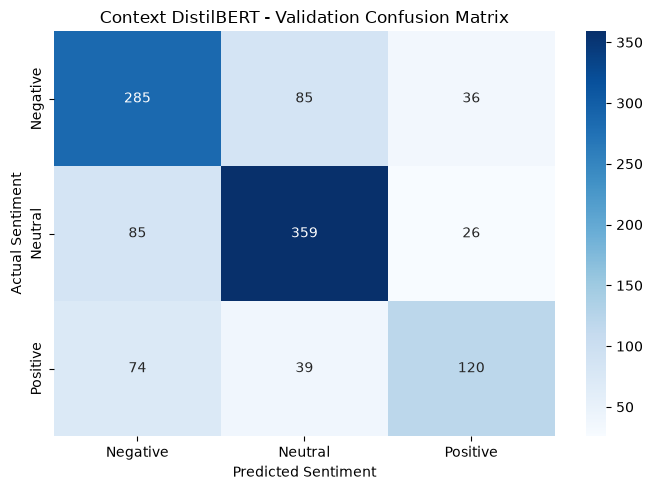

In [26]:
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import classification_report, confusion_matrix
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Load the best saved contextual checkpoint
best_context_model = AutoModelForSequenceClassification.from_pretrained(
    CONTEXT_MODEL_SAVE_PATH
).to(device)

best_context_model.eval()

context_preds = []
context_true = []

# Validation evaluation
with torch.no_grad():
    for batch in dev_context_loader:
        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        outputs = best_context_model(**batch)
        predictions = torch.argmax(outputs.logits, dim=1)

        context_preds.extend(
            predictions.cpu().numpy()
        )
        context_true.extend(
            batch["labels"].cpu().numpy()
        )

# Class-wise report
print("CONTEXT DISTILBERT - CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        context_true,
        context_preds,
        target_names=["Negative", "Neutral", "Positive"],
        digits=4
    )
)

# Confusion matrix
cm_context = confusion_matrix(
    context_true,
    context_preds
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_context,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Context DistilBERT - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

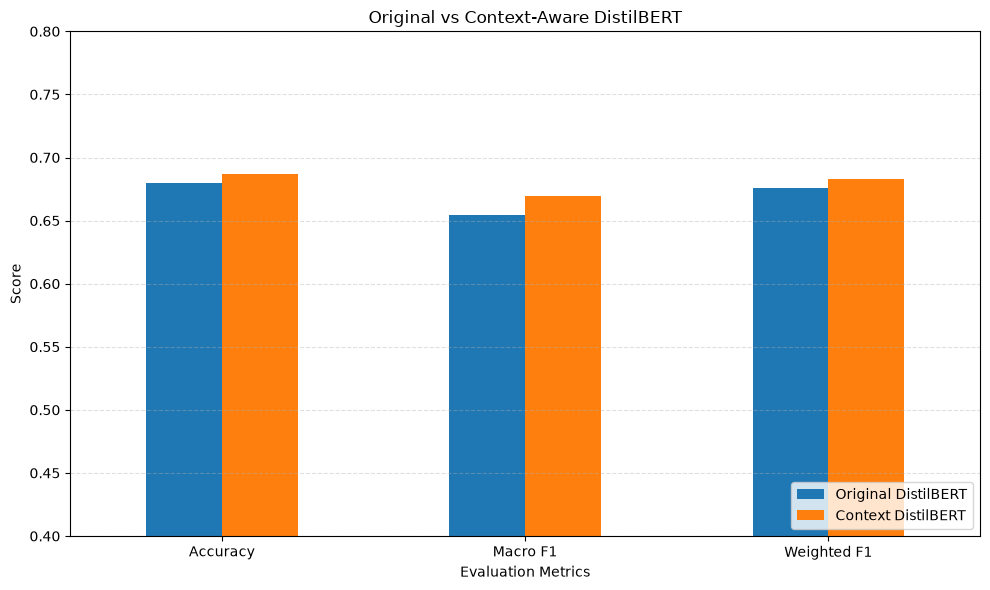

,Metric,Original DistilBERT,Context DistilBERT
0,Accuracy,0.6799,0.6871
1,Macro F1,0.6545,0.6694
2,Weighted F1,0.6755,0.6832


In [27]:
import pandas as pd
import matplotlib.pyplot as plt

model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "Weighted F1"],
    "Original DistilBERT": [0.6799, 0.6545, 0.6755],
    "Context DistilBERT": [0.6871, 0.6694, 0.6832]
})

model_comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0.40, 0.80),
    rot=0
)

plt.title("Original vs Context-Aware DistilBERT")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

display(model_comparison)

# 16. RoBERTa-base Sentiment Classification

In this experiment, we fine-tune RoBERTa-base on the MELD dataset
for three-class sentiment classification.

We compare its performance with DistilBERT and Context DistilBERT
using the same validation dataset.

In [28]:
from transformers import AutoTokenizer

ROBERTA_MODEL_NAME = "FacebookAI/roberta-base"

roberta_tokenizer = AutoTokenizer.from_pretrained(
    ROBERTA_MODEL_NAME
)

print("RoBERTa tokenizer loaded successfully!")
print("Vocabulary size:", roberta_tokenizer.vocab_size)

RoBERTa tokenizer loaded successfully!
Vocabulary size: 50265


In [29]:
ROBERTA_MAX_LENGTH = 128

roberta_train_encodings = roberta_tokenizer(
    train_df["Utterance"].fillna("").tolist(),
    truncation=True,
    padding="max_length",
    max_length=ROBERTA_MAX_LENGTH
)

roberta_dev_encodings = roberta_tokenizer(
    dev_df["Utterance"].fillna("").tolist(),
    truncation=True,
    padding="max_length",
    max_length=ROBERTA_MAX_LENGTH
)

roberta_test_encodings = roberta_tokenizer(
    test_df["Utterance"].fillna("").tolist(),
    truncation=True,
    padding="max_length",
    max_length=ROBERTA_MAX_LENGTH
)

print("RoBERTa tokenization completed!")
print("Training samples:", len(roberta_train_encodings["input_ids"]))
print("Validation samples:", len(roberta_dev_encodings["input_ids"]))
print("Test samples:", len(roberta_test_encodings["input_ids"]))
print("Sequence length:", ROBERTA_MAX_LENGTH)

RoBERTa tokenization completed!
Training samples: 9989
Validation samples: 1109
Test samples: 2610
Sequence length: 128


In [30]:
import torch
import numpy as np
import pandas as pd
import os
from pathlib import Path

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

ROBERTA_MODEL_NAME = "FacebookAI/roberta-base"
ROBERTA_MAX_LENGTH = 128

ROBERTA_BATCH_SIZE = 4
ROBERTA_EVAL_BATCH_SIZE = 8
ROBERTA_EPOCHS = 3
ROBERTA_LR = 2e-5
ROBERTA_WEIGHT_DECAY = 0.01

ROBERTA_SAVE_PATH = project_root / "models" / "roberta_meld_sentiment"
ROBERTA_SAVE_PATH.mkdir(parents=True, exist_ok=True)

roberta_tokenizer = AutoTokenizer.from_pretrained(ROBERTA_MODEL_NAME)

# Automatically identify the sentiment column
possible_labels = [
    "sentiment", "Sentiment",
    "sentiment_label", "Sentiment_Label",
    "sentiment_encoded", "SentimentEncoded"
]

label_column = next(
    (col for col in possible_labels if col in train_df.columns),
    None
)

if label_column is None:
    raise ValueError(
        f"Sentiment column not found. Available columns: {train_df.columns.tolist()}"
    )

print("Detected sentiment column:", label_column)

label_mapping = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

def convert_labels(df):
    values = df[label_column]

    if pd.api.types.is_numeric_dtype(values):
        return values.astype(int).tolist()

    return values.astype(str).str.lower().map(label_mapping).tolist()

roberta_train_labels = convert_labels(train_df)
roberta_dev_labels = convert_labels(dev_df)
roberta_test_labels = convert_labels(test_df)

print("Tokenizer loaded:", ROBERTA_MODEL_NAME)
print("Training samples:", len(train_df))
print("Validation samples:", len(dev_df))
print("Test samples:", len(test_df))
print("Label mapping:", label_mapping)

Detected sentiment column: Sentiment
Tokenizer loaded: FacebookAI/roberta-base
Training samples: 9989
Validation samples: 1109
Test samples: 2610
Label mapping: {'negative': 0, 'neutral': 1, 'positive': 2}


In [31]:
def tokenize_roberta_data(df):
    return roberta_tokenizer(
        df["Utterance"].fillna("").astype(str).tolist(),
        truncation=True,
        padding="max_length",
        max_length=ROBERTA_MAX_LENGTH
    )

roberta_train_encodings = tokenize_roberta_data(train_df)
roberta_dev_encodings = tokenize_roberta_data(dev_df)
roberta_test_encodings = tokenize_roberta_data(test_df)


class RoBERTaMELDDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx], dtype=torch.long)
            for key, val in self.encodings.items()
        }
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


roberta_train_dataset = RoBERTaMELDDataset(
    roberta_train_encodings, roberta_train_labels
)

roberta_dev_dataset = RoBERTaMELDDataset(
    roberta_dev_encodings, roberta_dev_labels
)

roberta_test_dataset = RoBERTaMELDDataset(
    roberta_test_encodings, roberta_test_labels
)

roberta_train_loader = DataLoader(
    roberta_train_dataset,
    batch_size=ROBERTA_BATCH_SIZE,
    shuffle=True
)

roberta_dev_loader = DataLoader(
    roberta_dev_dataset,
    batch_size=ROBERTA_EVAL_BATCH_SIZE,
    shuffle=False
)

roberta_test_loader = DataLoader(
    roberta_test_dataset,
    batch_size=ROBERTA_EVAL_BATCH_SIZE,
    shuffle=False
)

print("RoBERTa DataLoaders created successfully!")
print("Train batches:", len(roberta_train_loader))
print("Validation batches:", len(roberta_dev_loader))
print("Test batches:", len(roberta_test_loader))

RoBERTa DataLoaders created successfully!
Train batches: 2498
Validation batches: 139
Test batches: 327


In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

roberta_model = AutoModelForSequenceClassification.from_pretrained(
    ROBERTA_MODEL_NAME,
    num_labels=3,
    id2label={
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    },
    label2id={
        "Negative": 0,
        "Neutral": 1,
        "Positive": 2
    }
).to(device)

print("RoBERTa model loaded!")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa model loaded!
Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
VRAM: 8.55 GB


In [33]:
from tqdm.auto import tqdm
from torch.optim import AdamW

roberta_optimizer = AdamW(
    roberta_model.parameters(),
    lr=ROBERTA_LR,
    weight_decay=ROBERTA_WEIGHT_DECAY
)

total_training_steps = len(roberta_train_loader) * ROBERTA_EPOCHS

roberta_scheduler = get_linear_schedule_with_warmup(
    roberta_optimizer,
    num_warmup_steps=int(0.1 * total_training_steps),
    num_training_steps=total_training_steps
)


def evaluate_roberta(model, loader):
    model.eval()

    all_preds = []
    all_labels = []
    total_loss = 0

    with torch.no_grad():
        for batch in loader:
            batch = {
                k: v.to(device)
                for k, v in batch.items()
            }

            outputs = model(**batch)

            total_loss += outputs.loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch["labels"].cpu().numpy())

    return {
        "loss": total_loss / len(loader),
        "accuracy": accuracy_score(all_labels, all_preds),
        "macro_f1": f1_score(all_labels, all_preds, average="macro"),
        "weighted_f1": f1_score(all_labels, all_preds, average="weighted"),
        "predictions": all_preds,
        "labels": all_labels
    }


roberta_history = []
best_roberta_f1 = 0
patience = 2
epochs_without_improvement = 0

for epoch in range(ROBERTA_EPOCHS):

    roberta_model.train()
    total_train_loss = 0

    progress_bar = tqdm(
        roberta_train_loader,
        desc=f"RoBERTa Epoch {epoch+1}/{ROBERTA_EPOCHS}"
    )

    for batch in progress_bar:

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        roberta_optimizer.zero_grad()

        outputs = roberta_model(**batch)
        loss = outputs.loss

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            roberta_model.parameters(),
            max_norm=1.0
        )

        roberta_optimizer.step()
        roberta_scheduler.step()

        total_train_loss += loss.item()

        progress_bar.set_postfix(loss=loss.item())

    avg_train_loss = total_train_loss / len(roberta_train_loader)

    val_metrics = evaluate_roberta(
        roberta_model,
        roberta_dev_loader
    )

    epoch_results = {
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_weighted_f1": val_metrics["weighted_f1"]
    }

    roberta_history.append(epoch_results)

    print(f"\nEpoch {epoch+1} Results")
    print("-" * 50)
    print(f"Train Loss:     {avg_train_loss:.4f}")
    print(f"Validation Loss:{val_metrics['loss']:.4f}")
    print(f"Accuracy:       {val_metrics['accuracy']:.4f}")
    print(f"Macro F1:       {val_metrics['macro_f1']:.4f}")
    print(f"Weighted F1:     {val_metrics['weighted_f1']:.4f}")

    if val_metrics["macro_f1"] > best_roberta_f1:

        best_roberta_f1 = val_metrics["macro_f1"]
        epochs_without_improvement = 0

        roberta_model.save_pretrained(ROBERTA_SAVE_PATH)
        roberta_tokenizer.save_pretrained(ROBERTA_SAVE_PATH)

        print("Best RoBERTa checkpoint saved!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

print("\nRoBERTa training completed!")
print("Best Validation Macro F1:", round(best_roberta_f1, 4))

RoBERTa Epoch 1/3:   0%|          | 0/2498 [00:00<?, ?it/s]


Epoch 1 Results
--------------------------------------------------
Train Loss:     0.8787
Validation Loss:0.8776
Accuracy:       0.6646
Macro F1:       0.6415
Weighted F1:     0.6621


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best RoBERTa checkpoint saved!


RoBERTa Epoch 2/3:   0%|          | 0/2498 [00:00<?, ?it/s]


Epoch 2 Results
--------------------------------------------------
Train Loss:     0.7545
Validation Loss:0.8213
Accuracy:       0.6808
Macro F1:       0.6611
Weighted F1:     0.6798


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best RoBERTa checkpoint saved!


RoBERTa Epoch 3/3:   0%|          | 0/2498 [00:00<?, ?it/s]


Epoch 3 Results
--------------------------------------------------
Train Loss:     0.6671
Validation Loss:1.0863
Accuracy:       0.6781
Macro F1:       0.6589
Weighted F1:     0.6752

RoBERTa training completed!
Best Validation Macro F1: 0.6611


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

ROBERTA - VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.6472    0.6281    0.6375       406
     Neutral     0.7531    0.7787    0.7657       470
    Positive     0.5852    0.5751    0.5801       233

    accuracy                         0.6808      1109
   macro avg     0.6618    0.6606    0.6611      1109
weighted avg     0.6790    0.6808    0.6798      1109



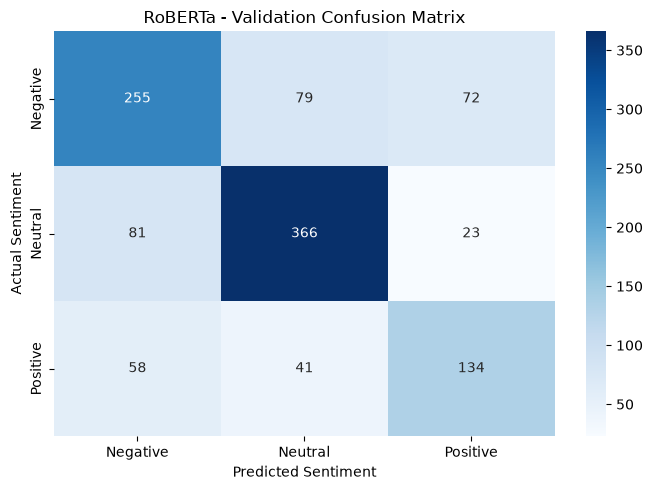

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

best_roberta_model = AutoModelForSequenceClassification.from_pretrained(
    ROBERTA_SAVE_PATH
).to(device)

roberta_val_results = evaluate_roberta(
    best_roberta_model,
    roberta_dev_loader
)

print("ROBERTA - VALIDATION CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        roberta_val_results["labels"],
        roberta_val_results["predictions"],
        target_names=["Negative", "Neutral", "Positive"],
        digits=4
    )
)

cm_roberta = confusion_matrix(
    roberta_val_results["labels"],
    roberta_val_results["predictions"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_roberta,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("RoBERTa - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_weighted_f1
0,1,0.878698,0.877554,0.664563,0.641511,0.662146
1,2,0.754456,0.821325,0.680794,0.661092,0.679765
2,3,0.667085,1.086315,0.678088,0.658921,0.675207


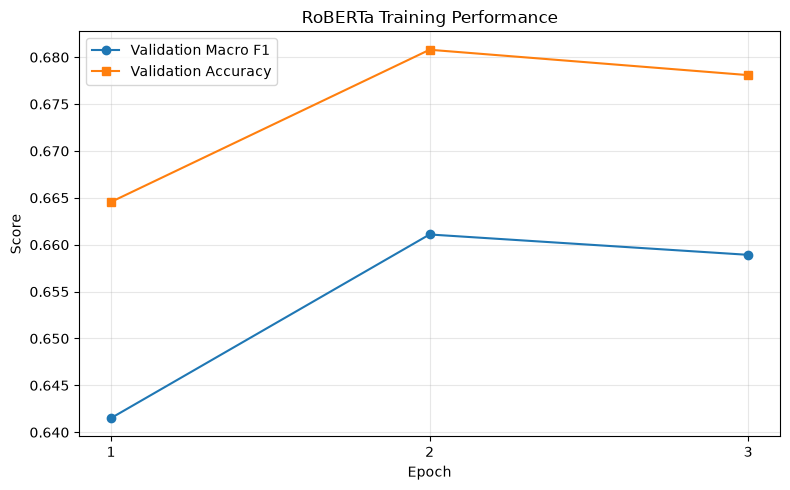

In [35]:
roberta_history_df = pd.DataFrame(roberta_history)

display(roberta_history_df)

plt.figure(figsize=(8, 5))
plt.plot(
    roberta_history_df["epoch"],
    roberta_history_df["val_macro_f1"],
    marker="o",
    label="Validation Macro F1"
)

plt.plot(
    roberta_history_df["epoch"],
    roberta_history_df["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("RoBERTa Training Performance")
plt.xticks(roberta_history_df["epoch"])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()